In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [47]:
# Load dataset
df = pd.read_csv("../data/raw/smartcart_customers.csv")

## Handling missing value

In [48]:
# Fill missing income with median
df["Income"] = df["Income"].fillna(df["Income"].median())
print(df.isnull().sum())

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64


## Drop Unnecessary Features

In [49]:
df = df.drop(columns=["ID", "Complain", "Response"], axis = 1)
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5


## Feature Engineering

In [50]:
# Convert date column
df["Dt_Customer"] = pd.to_datetime(
    df["Dt_Customer"],
    format="%d-%m-%Y"
)

# Reference date
reference_date = df["Dt_Customer"].max()

# Calculate age
df["Age"] = reference_date.year - df["Year_Birth"]

# Calculate customer tenure
df["Customer_Tenure"] = (
    reference_date - df["Dt_Customer"]
).dt.days

# Drop original columns
df.drop(
    columns=["Year_Birth", "Dt_Customer"],
    inplace=True
)

In [51]:
# Create Total Spending
df["Total_Spending"] = df[
    [
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"
    ]
].sum(axis=1)

df.drop(
    columns=[
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"
    ],
    inplace=True
)

In [52]:
# Total Children
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

df.drop(columns=["Kidhome", "Teenhome"], inplace=True)

In [53]:
df.head()

,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Customer_Tenure,Total_Spending,Total_Children
0,Graduation,Single,58138.0,58,3,8,10,4,7,57,663,1617,0
1,Graduation,Single,46344.0,38,2,1,1,2,5,60,113,27,2
2,Graduation,Together,71613.0,26,1,8,2,10,4,49,312,776,0
3,Graduation,Together,26646.0,26,2,2,0,4,6,30,139,53,1
4,PhD,Married,58293.0,94,5,5,3,6,5,33,161,422,1


## Handling Outliers

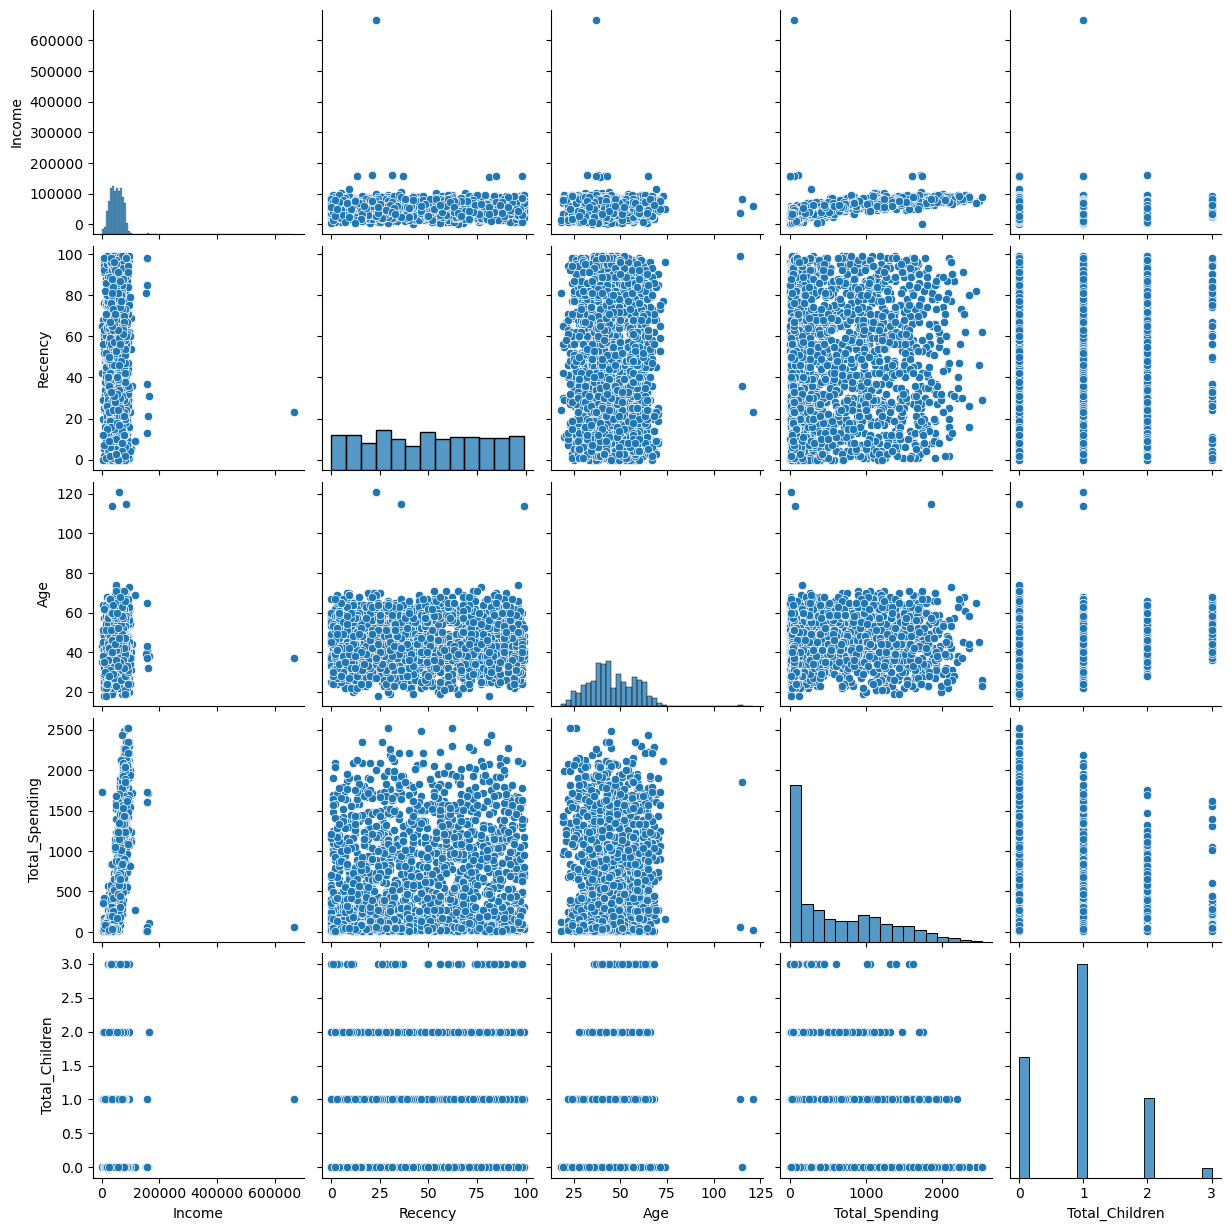

In [54]:
selected_cols = ["Income", "Recency", "Age", "Total_Spending", "Total_Children"]

sns.pairplot(df[selected_cols])
plt.show()

In [55]:
# drop outlier rows
df.drop(df[df["Income"] > 600000].index, inplace=True)

df.drop(df[df["Age"] > 90].index, inplace=True)

In [56]:
df_cleaned = df

## Correlation matrix

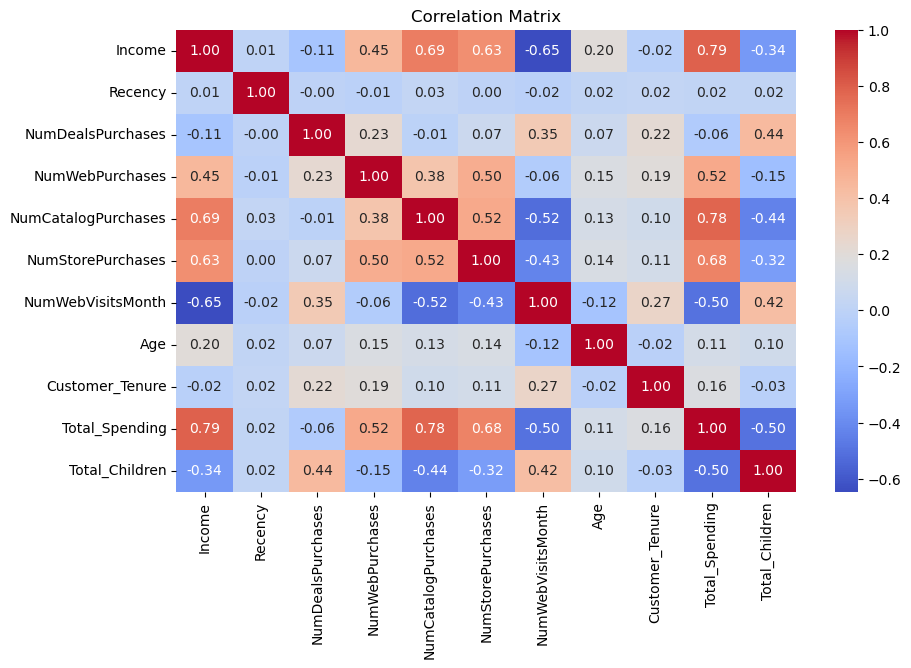

In [57]:
num_cols = df_cleaned.select_dtypes(include = ["number"]).columns

plt.figure(figsize=(10, 6))

corr = df_cleaned[num_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap = "coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

## One Hot Encoding

In [58]:
# Clean marital status
df_cleaned["Marital_Status"] = df_cleaned["Marital_Status"].replace({
    "Married": "Partner",
    "Together": "Partner",
    "Single": "Single",
    "Alone": "Single",
    "Divorced": "Previously_Married",
    "Widow": "Previously_Married",
    "Absurd": "Unknown",
    "YOLO": "Unknown"
})

education_map = {
    "Basic": "Undergraduate",
    "Graduation": "Graduate",
    "2n Cycle": "Postgraduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate"
}

df_cleaned["Education"] = df_cleaned["Education"].replace(education_map)

# One-Hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=["Education", "Marital_Status"],
    dtype=int
)

In [59]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Customer_Tenure,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Marital_Status_Partner,Marital_Status_Previously_Married,Marital_Status_Single,Marital_Status_Unknown
0,58138.0,58,3,8,10,4,7,57,663,1617,0,1,0,0,0,0,1,0
1,46344.0,38,2,1,1,2,5,60,113,27,2,1,0,0,0,0,1,0
2,71613.0,26,1,8,2,10,4,49,312,776,0,1,0,0,1,0,0,0
3,26646.0,26,2,2,0,4,6,30,139,53,1,1,0,0,1,0,0,0
4,58293.0,94,5,5,3,6,5,33,161,422,1,0,1,0,1,0,0,0


# Save Cleaned Dataset

In [60]:
df_encoded.to_csv("../data/processed/smartcart_customers_cleaned.csv", index=False)